# Etape 3 - Entraînement et comparaison des modèles

## 3-1 Entraîner au moins 3 modèles

In [100]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

In [101]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'SVC': SVC(probability=True, random_state=RANDOM_STATE),
}

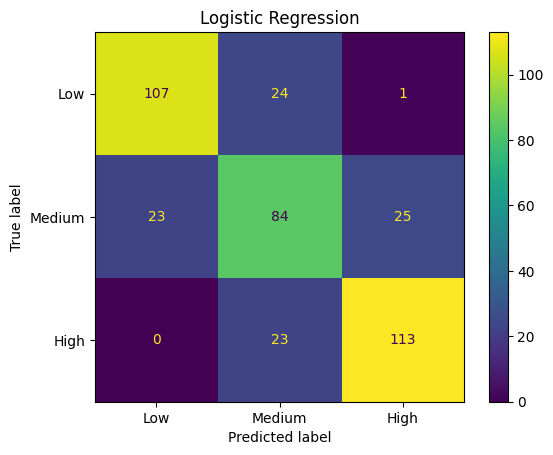

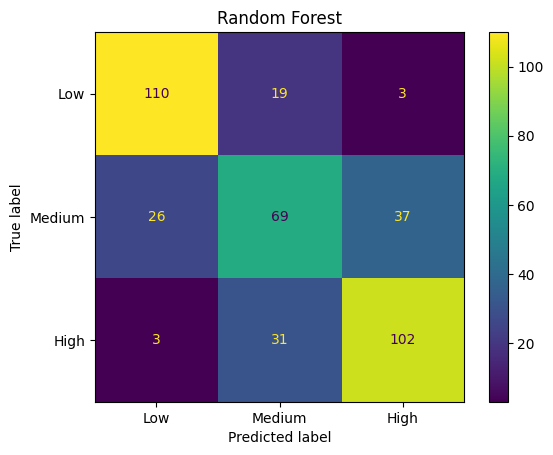

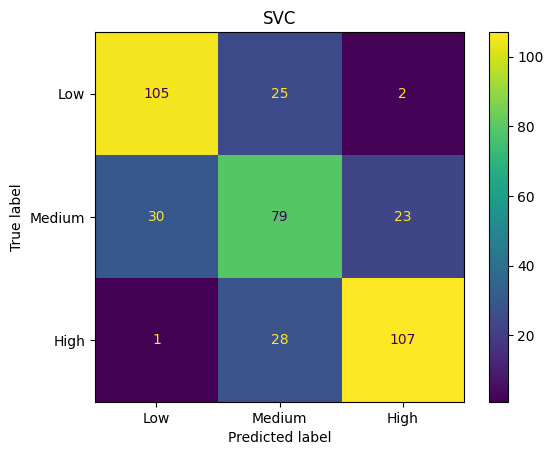

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.760,0.759,0.759,0.759,0.914
Random Forest,0.702,0.697,0.702,0.698,0.861
SVC,0.728,0.727,0.727,0.727,0.888


In [102]:
results = {}
for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)

    results[name] = {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, average='macro'),
        'recall': recall_score(y_test, y_pred, average='macro'),
        'f1': f1_score(y_test, y_pred, average='macro'),
        'roc_auc': roc_auc_score(y_test, y_proba, multi_class='ovr'),
    }

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=['Low', 'Medium', 'High'])
    plt.title(name)
    plt.show()
    
pd.DataFrame(results).T.round(3)